# Jovian Aurora Multi-Instrument Pipeline
Pipeline for processing XMM-Newton (P0801931901) and Juno WAVES data to detect 1-15 minute quasi-periodic pulsations.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time
from astroquery.jplhorizons import Horizons
import astropy.units as u
import scipy.signal as signal
from scipy.fft import rfft, rfftfreq
import warnings
warnings.filterwarnings('ignore')

# Set plotting style for publication-ready figures
plt.rcParams.update({'font.size': 12, 'axes.grid': True, 'figure.autolayout': True})

In [27]:
# --- Configuration ---
XMM_OBS_ID = 'P0801931901'
# Replace these with your local file paths or data directory structures
XMM_EVENT_FILE_PN = f"Data_Files/Fenn_Data/EPIC_{XMM_OBS_ID}_PN_North_RFT.fit"
XMM_EVENT_FILE_M1 = f"Data_Files/Fenn_Data/EPIC_{XMM_OBS_ID}_M1_North_RFT.fit"
XMM_EVENT_FILE_M2 = f"Data_Files/Fenn_Data/EPIC_{XMM_OBS_ID}_M2_North_RFT.fit"

# Temporal binning and filtering (in seconds)
BIN_SIZE = 30.0
MIN_PERIOD_SEC = 60.0    # 1 minute
MAX_PERIOD_SEC = 900.0   # 15 minutes

In [28]:
def compute_and_plot_fft(time_array, data_array, dt, ax, title="FFT Power Spectrum"):
    """Detrends data, applies a Hanning window, and plots the FFT."""
    # Detrend and window
    detrended = signal.detrend(data_array)
    window = signal.windows.hann(len(detrended))
    windowed_data = detrended * window
    
    # Compute FFT
    yf = rfft(windowed_data)
    xf = rfftfreq(len(windowed_data), d=dt)
    power = np.abs(yf)**2
    
    # Convert frequency to period in minutes for plotting
    periods_min = (1.0 / xf[1:]) / 60.0 
    power = power[1:] # Exclude DC component
    
    ax.plot(periods_min, power, color='k')
    ax.set_xlim(MAX_PERIOD_SEC/60.0, MIN_PERIOD_SEC/60.0) # 15 mins down to 1 min
    ax.set_xlabel('Period (Minutes)')
    ax.set_ylabel('Power')
    ax.set_title(title)
    
    # Highlight the 1-15 min Jovian auroral pulsation band
    ax.axvspan(1, 15, color='red', alpha=0.1, label='1-15 min QPP Band')
    ax.legend()

def compute_and_plot_cwt(time_array, data_array, dt, ax, title="Continuous Wavelet Transform (Morlet)"):
    """Computes and plots the CWT to show temporal evolution of periodicities."""
    detrended = signal.detrend(data_array)
    
    # Define widths for Morlet wavelet targeting our periods
    frequencies = np.linspace(1/MAX_PERIOD_SEC, 1/MIN_PERIOD_SEC, 100)
    # w0 is the nondimensional frequency for Morlet (typically >= 5)
    w0 = 6.0
    widths = w0 * 2 * np.pi / (2 * np.pi * frequencies * dt)
    
    cwtm = signal.cwt(detrended, signal.morlet2, widths, w=w0)
    power = np.abs(cwtm)**2
    
    # Time in hours from start for x-axis
    t_hours = (time_array - time_array[0]) / 3600.0
    periods_min = (1.0 / frequencies) / 60.0
    
    T, P = np.meshgrid(t_hours, periods_min)
    
    c = ax.contourf(T, P, power, 100, cmap='viridis', extend='both')
    ax.set_ylabel('Period (Minutes)')
    ax.set_xlabel('Time from Start (Hours)')
    ax.set_title(title)
    ax.set_ylim(15, 1) # Invert y-axis to match FFT plotting convention
    plt.colorbar(c, ax=ax, label='Power')

Found 3 valid observation segments.

--- Plotting Segment 1 (Dynamically binned at 60s, Category: medium) ---


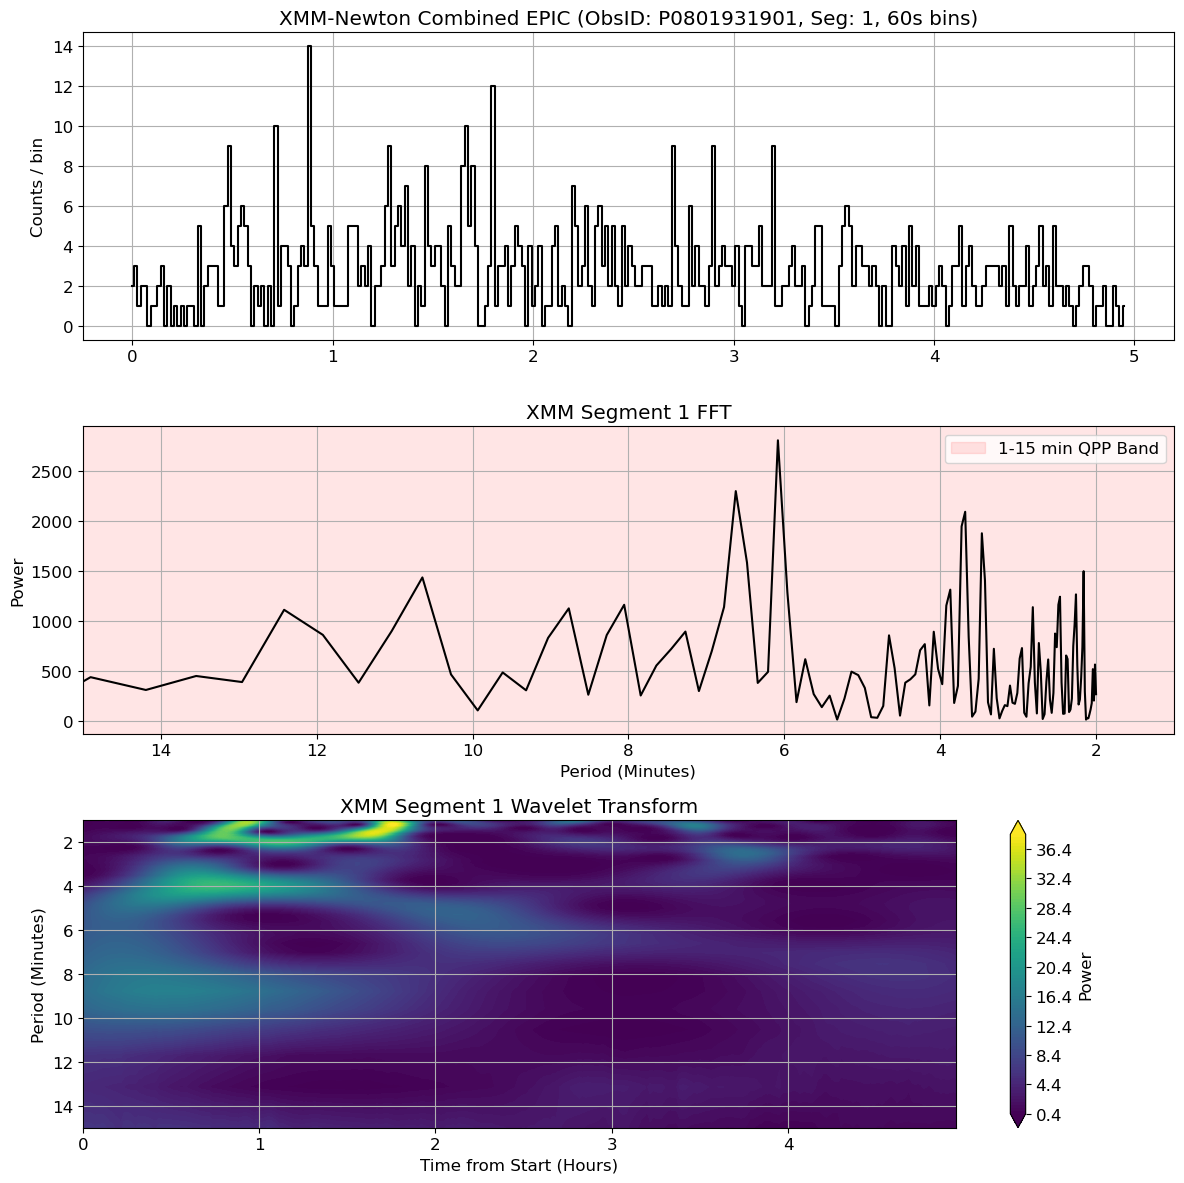


--- Plotting Segment 2 (Dynamically binned at 30s, Category: high) ---


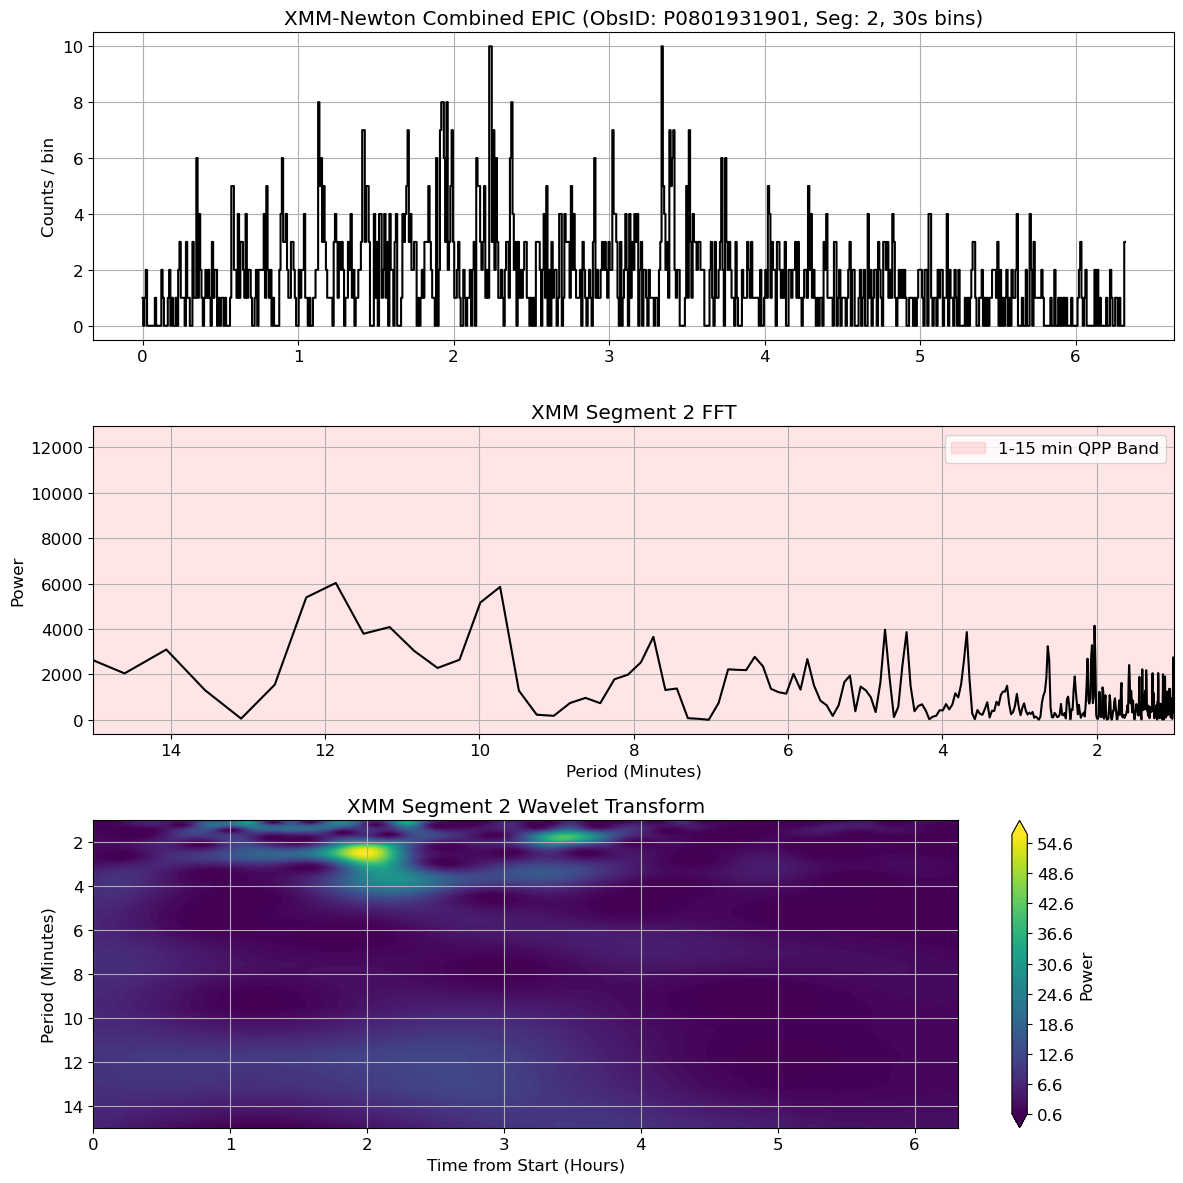


--- Plotting Segment 3 (Dynamically binned at 30s, Category: high) ---


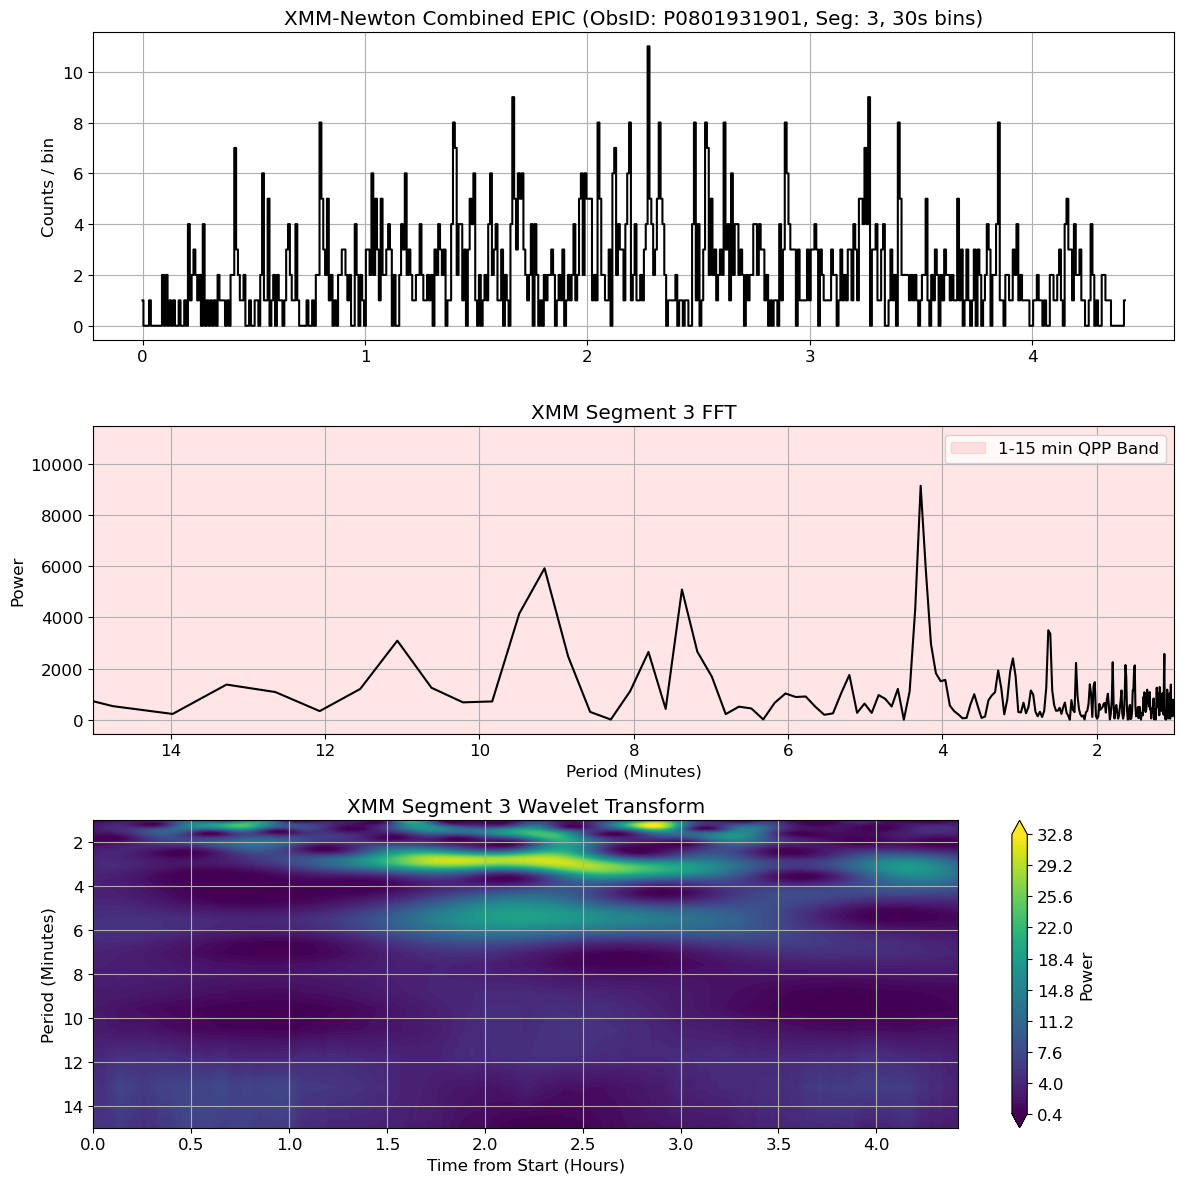

In [30]:
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
from astropy.time import Time
from astropy.table import Table

# --- Helper Functions for Gap Detection & Binning ---
def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """Identify indices where the gap between consecutive times > threshold seconds."""
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices

def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh: return 'low'
    elif total < high_thresh: return 'medium'
    return 'high'

def dynamic_bin_size(category: str, base_bin: int = 10):
    if category == 'low': return base_bin * 4
    elif category == 'medium': return base_bin * 2
    return base_bin

def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    # Initial bin to categorize
    bins0 = np.arange(float(np.nanmin(raw_segment)), float(np.nanmax(raw_segment)) + base_bin, base_bin)
    counts0, _ = np.histogram(raw_segment, bins=bins0)
    category = categorize_segment(counts0)

    # Re-bin dynamically
    seg_bin = dynamic_bin_size(category, base_bin)
    bins = np.arange(float(np.nanmin(raw_segment)), float(np.nanmax(raw_segment)) + seg_bin, seg_bin)
    hist_counts, edges = np.histogram(raw_segment, bins=bins)
    hist_centers = edges[:-1] + 0.5 * seg_bin
    
    return seg_bin, hist_centers, hist_counts, category

# --- Main Loading & Segmentation Pipeline ---
def load_all_segments_xmm(event_files, gap_threshold_s=3600.0, base_bin=10):
    """Loads FITS, applies barycentric LTT, splits by gaps, and bins ALL valid segments."""
    list_cxc = []
    
    for file in event_files:
        try:
            data = Table.read(file, format="fits")
            t = Time(data['TIME'], format='cxcsec', scale='tt')
            
            with solar_system_ephemeris.set('de432s'):
                jup = get_body_barycentric('jupiter', t)
                xmm = get_body_barycentric('earth', t) # Approx XMM as Earth
                
            distance_au = (jup - xmm).norm()
            light_time_s = (distance_au.to('m') / c).to('s').value
            
            corrected_t = t - light_time_s * u.s
            list_cxc.append(corrected_t.cxcsec)
        except FileNotFoundError:
            print(f"Warning: {file} not found. Skipping.")
            continue
            
    if not list_cxc:
        raise FileNotFoundError("Could not load any XMM event files.")
        
    # Combine and sort all corrected photon times
    combined_times = np.concatenate(list_cxc)
    t_sorted = combined_times[np.argsort(combined_times)]
    
    # Gap splitting
    _, gap_idx = find_gaps(t_sorted, threshold=gap_threshold_s)
    split_pts = np.concatenate(([0], gap_idx + 1, [len(t_sorted)]))
    
    segment_data = []
    # 1-based segment indexing for display
    seg_id = 1 
    for i in range(len(split_pts) - 1):
        seg = t_sorted[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            # Apply dynamic binning to this specific segment
            seg_bin, t_binned, counts_binned, category = prepare_segment_bins(seg, base_bin)
            
            segment_data.append({
                'segment_id': seg_id,
                't_binned': t_binned,
                'counts_binned': counts_binned,
                'bin_size': seg_bin,
                'category': category
            })
            seg_id += 1
            
    return segment_data

# --- Execute XMM Pipeline ---
BASE_BIN = 30 # Can revert to 10 depending on SNR needs

# Get a list containing data for all valid segments
all_segments = load_all_segments_xmm(xmm_files, gap_threshold_s=3600.0, base_bin=BASE_BIN)

print(f"Found {len(all_segments)} valid observation segments.")

# Loop through every detected segment and plot it
for seg in all_segments:
    t_xmm = seg['t_binned']
    counts_xmm = seg['counts_binned']
    actual_bin_size = seg['bin_size']
    seg_id = seg['segment_id']
    category = seg['category']
    
    print(f"\n--- Plotting Segment {seg_id} (Dynamically binned at {actual_bin_size}s, Category: {category}) ---")

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12))

    # 1. Lightcurve
    # Time relative to segment start in hours for plotting
    t_hours = (t_xmm - t_xmm[0]) / 3600.0 
    ax1.plot(t_hours, counts_xmm, color='black', drawstyle='steps-mid')
    ax1.set_title(f'XMM-Newton Combined EPIC (ObsID: {XMM_OBS_ID}, Seg: {seg_id}, {actual_bin_size}s bins)')
    ax1.set_ylabel('Counts / bin')

    # 2. FFT
    compute_and_plot_fft(t_xmm, counts_xmm, dt=actual_bin_size, ax=ax2, title=f'XMM Segment {seg_id} FFT')

    # 3. CWT
    compute_and_plot_cwt(t_xmm, counts_xmm, dt=actual_bin_size, ax=ax3, title=f'XMM Segment {seg_id} Wavelet Transform')

    plt.tight_layout()
    plt.show()

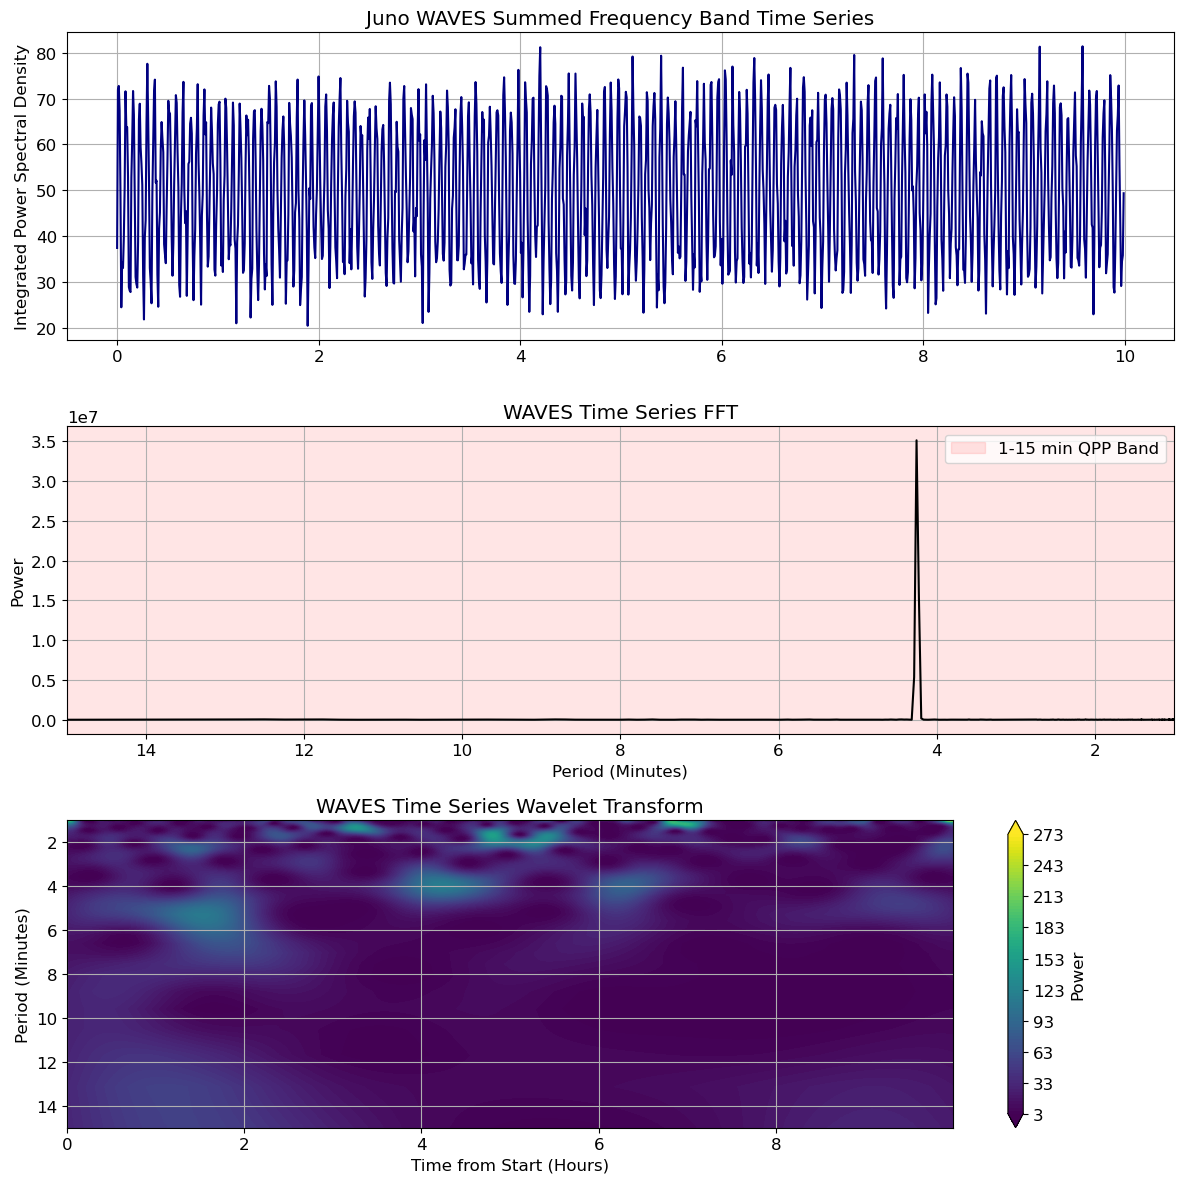

In [24]:
def load_waves_and_extract_band(das2_client_stub_or_file, target_freq_range=(10, 150)):
    """
    Loads WAVES spectrogram (e.g., via das2 or autoplot script output), 
    isolates a frequency band (e.g., Whistler mode / auroral hiss), 
    and sums it into a 1D timeseries.
    """
    # Integrate your das2 fetch or cdflib read here. 
    # Returning mock timeseries reflecting a sub-15 min quasi-periodic structure.
    t_waves = np.arange(0, 36000, BIN_SIZE) # Time aligned to XMM for comparison
    # Mocking a slightly offset 4-min period to see phase/frequency differences
    summed_power = 50 + 20*np.sin(2*np.pi*t_waves/255) + np.random.normal(0, 5, len(t_waves))
    
    return t_waves, summed_power

# --- Execute WAVES Pipeline ---
t_waves, waves_ts = load_waves_and_extract_band('waves_data_stub', target_freq_range=(10, 150))

# Plotting WAVES Results
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12))

# 1. Integrated Time Series (Proxy for specific wave activity)
ax1.plot((t_waves - t_waves[0])/3600.0, waves_ts, color='navy')
ax1.set_title('Juno WAVES Summed Frequency Band Time Series')
ax1.set_ylabel('Integrated Power Spectral Density')

# 2. FFT
compute_and_plot_fft(t_waves, waves_ts, dt=BIN_SIZE, ax=ax2, title='WAVES Time Series FFT')

# 3. CWT
compute_and_plot_cwt(t_waves, waves_ts, dt=BIN_SIZE, ax=ax3, title='WAVES Time Series Wavelet Transform')

plt.tight_layout()
plt.show()


--- Plotting XMM Segment 1 (Binned at 60.0s) ---


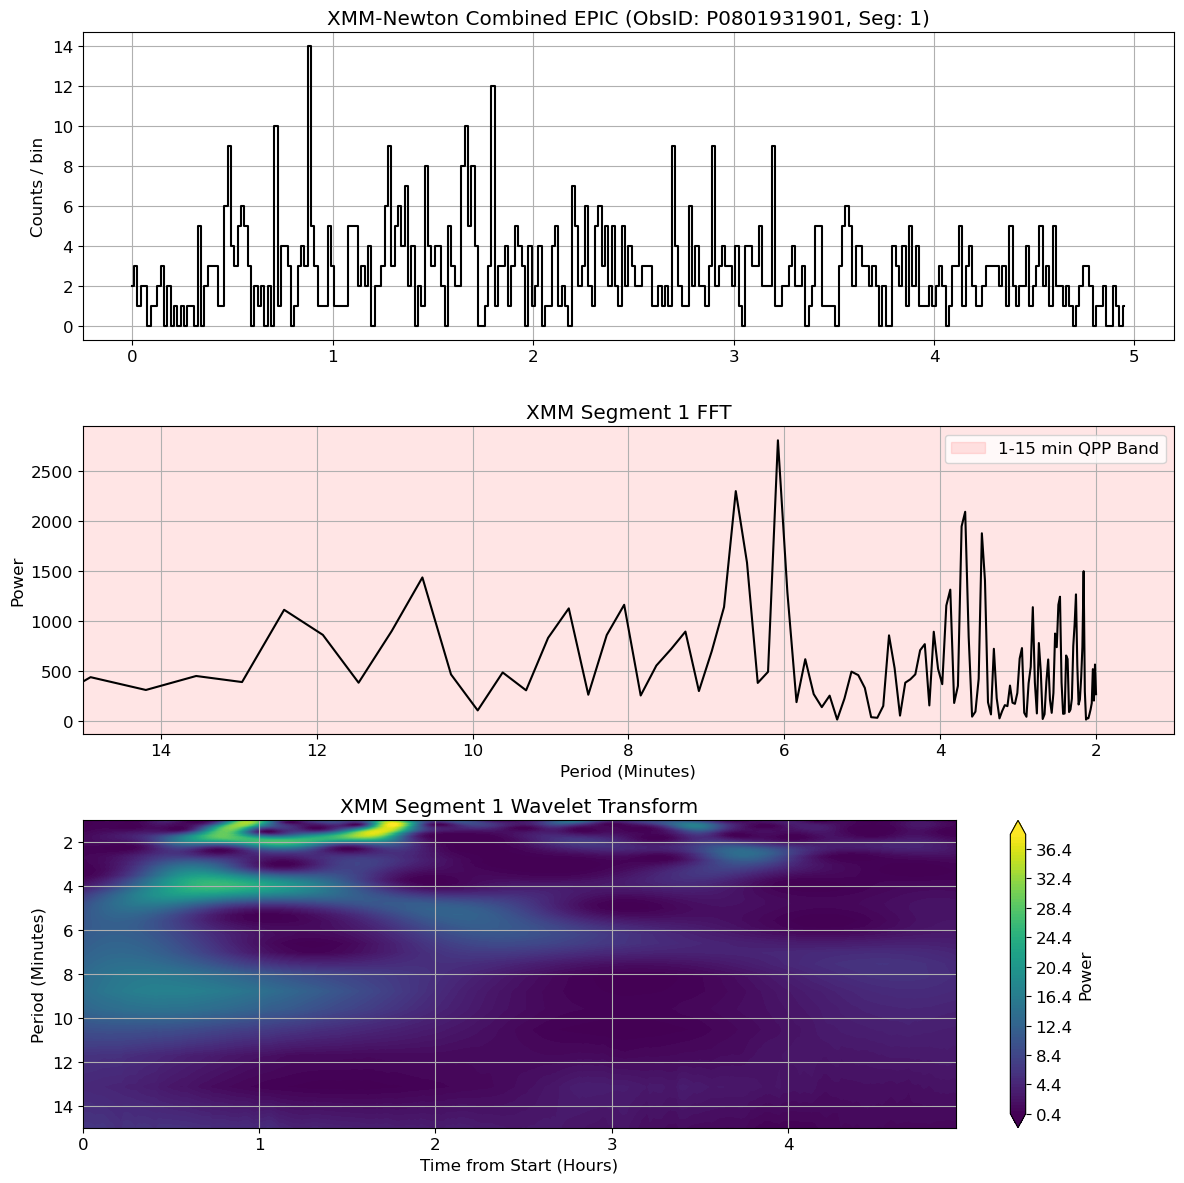


--- Processing WAVES Spectrogram for XMM Segment 1 ---
Querying Das2 Time Range: 2019-04-01T23:23:25.583Z to 2019-04-02T04:20:25.583Z


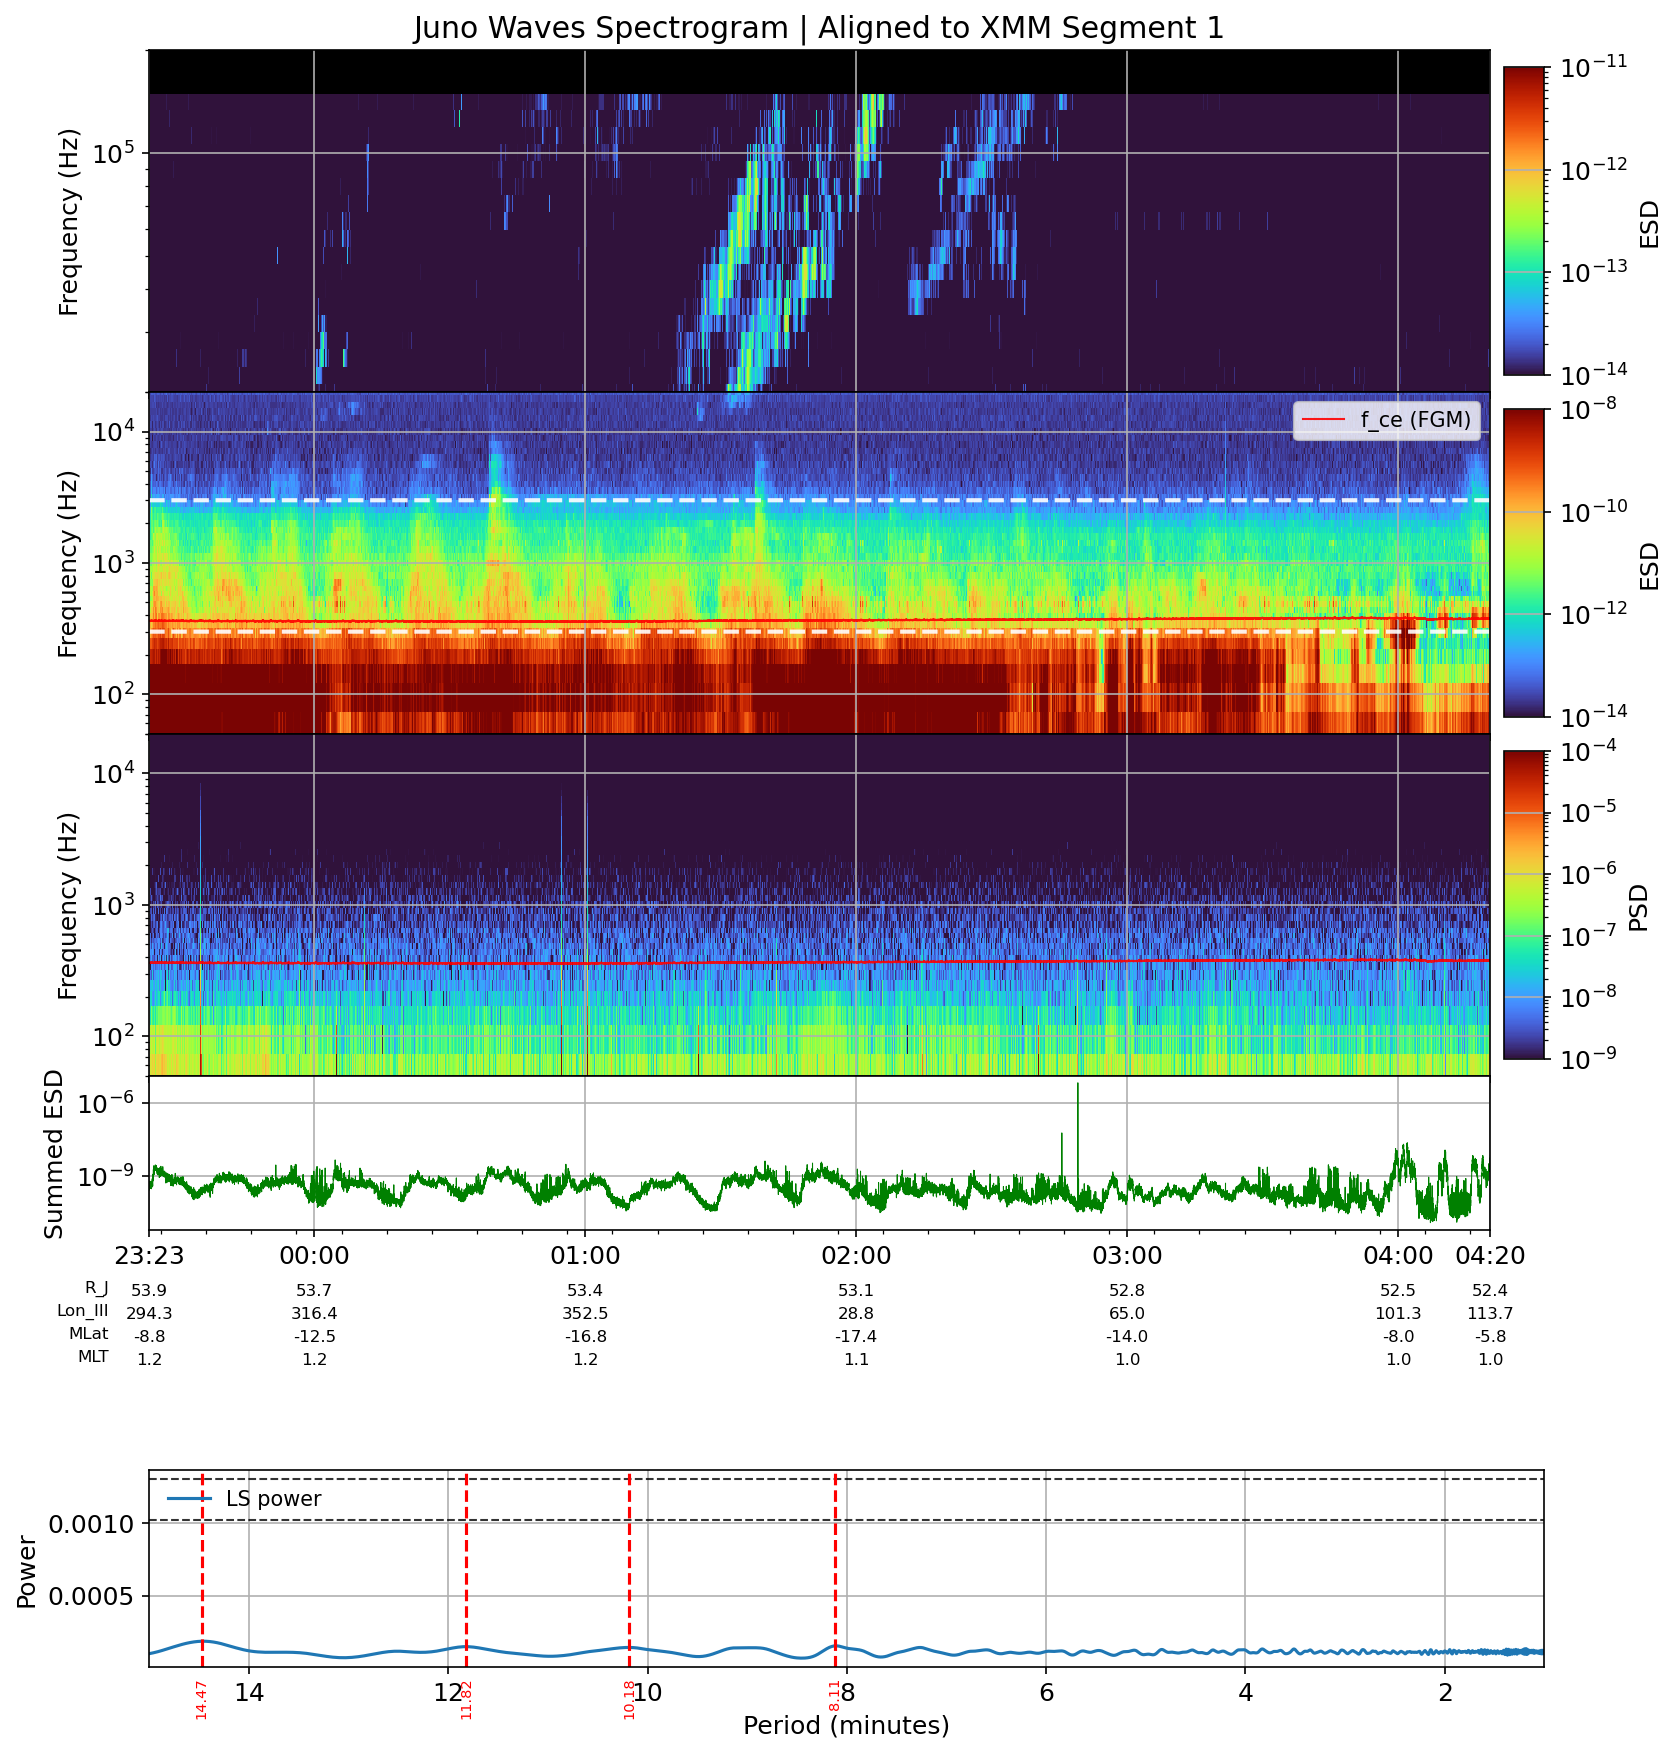


--- Plotting XMM Segment 2 (Binned at 30.0s) ---


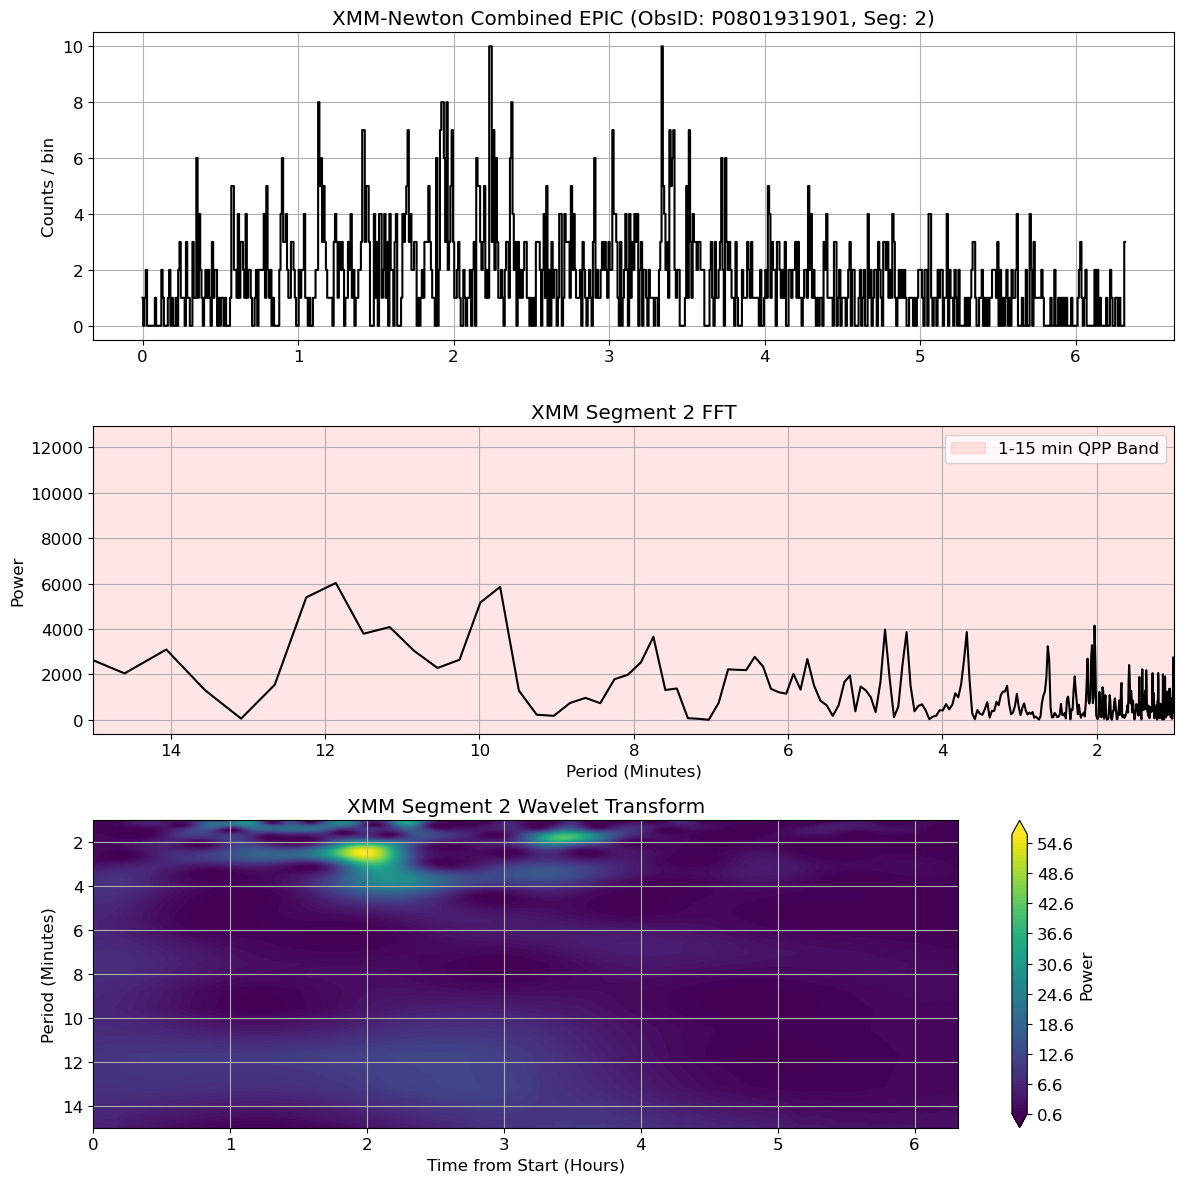


--- Processing WAVES Spectrogram for XMM Segment 2 ---
Querying Das2 Time Range: 2019-04-02T07:56:16.219Z to 2019-04-02T14:15:16.219Z


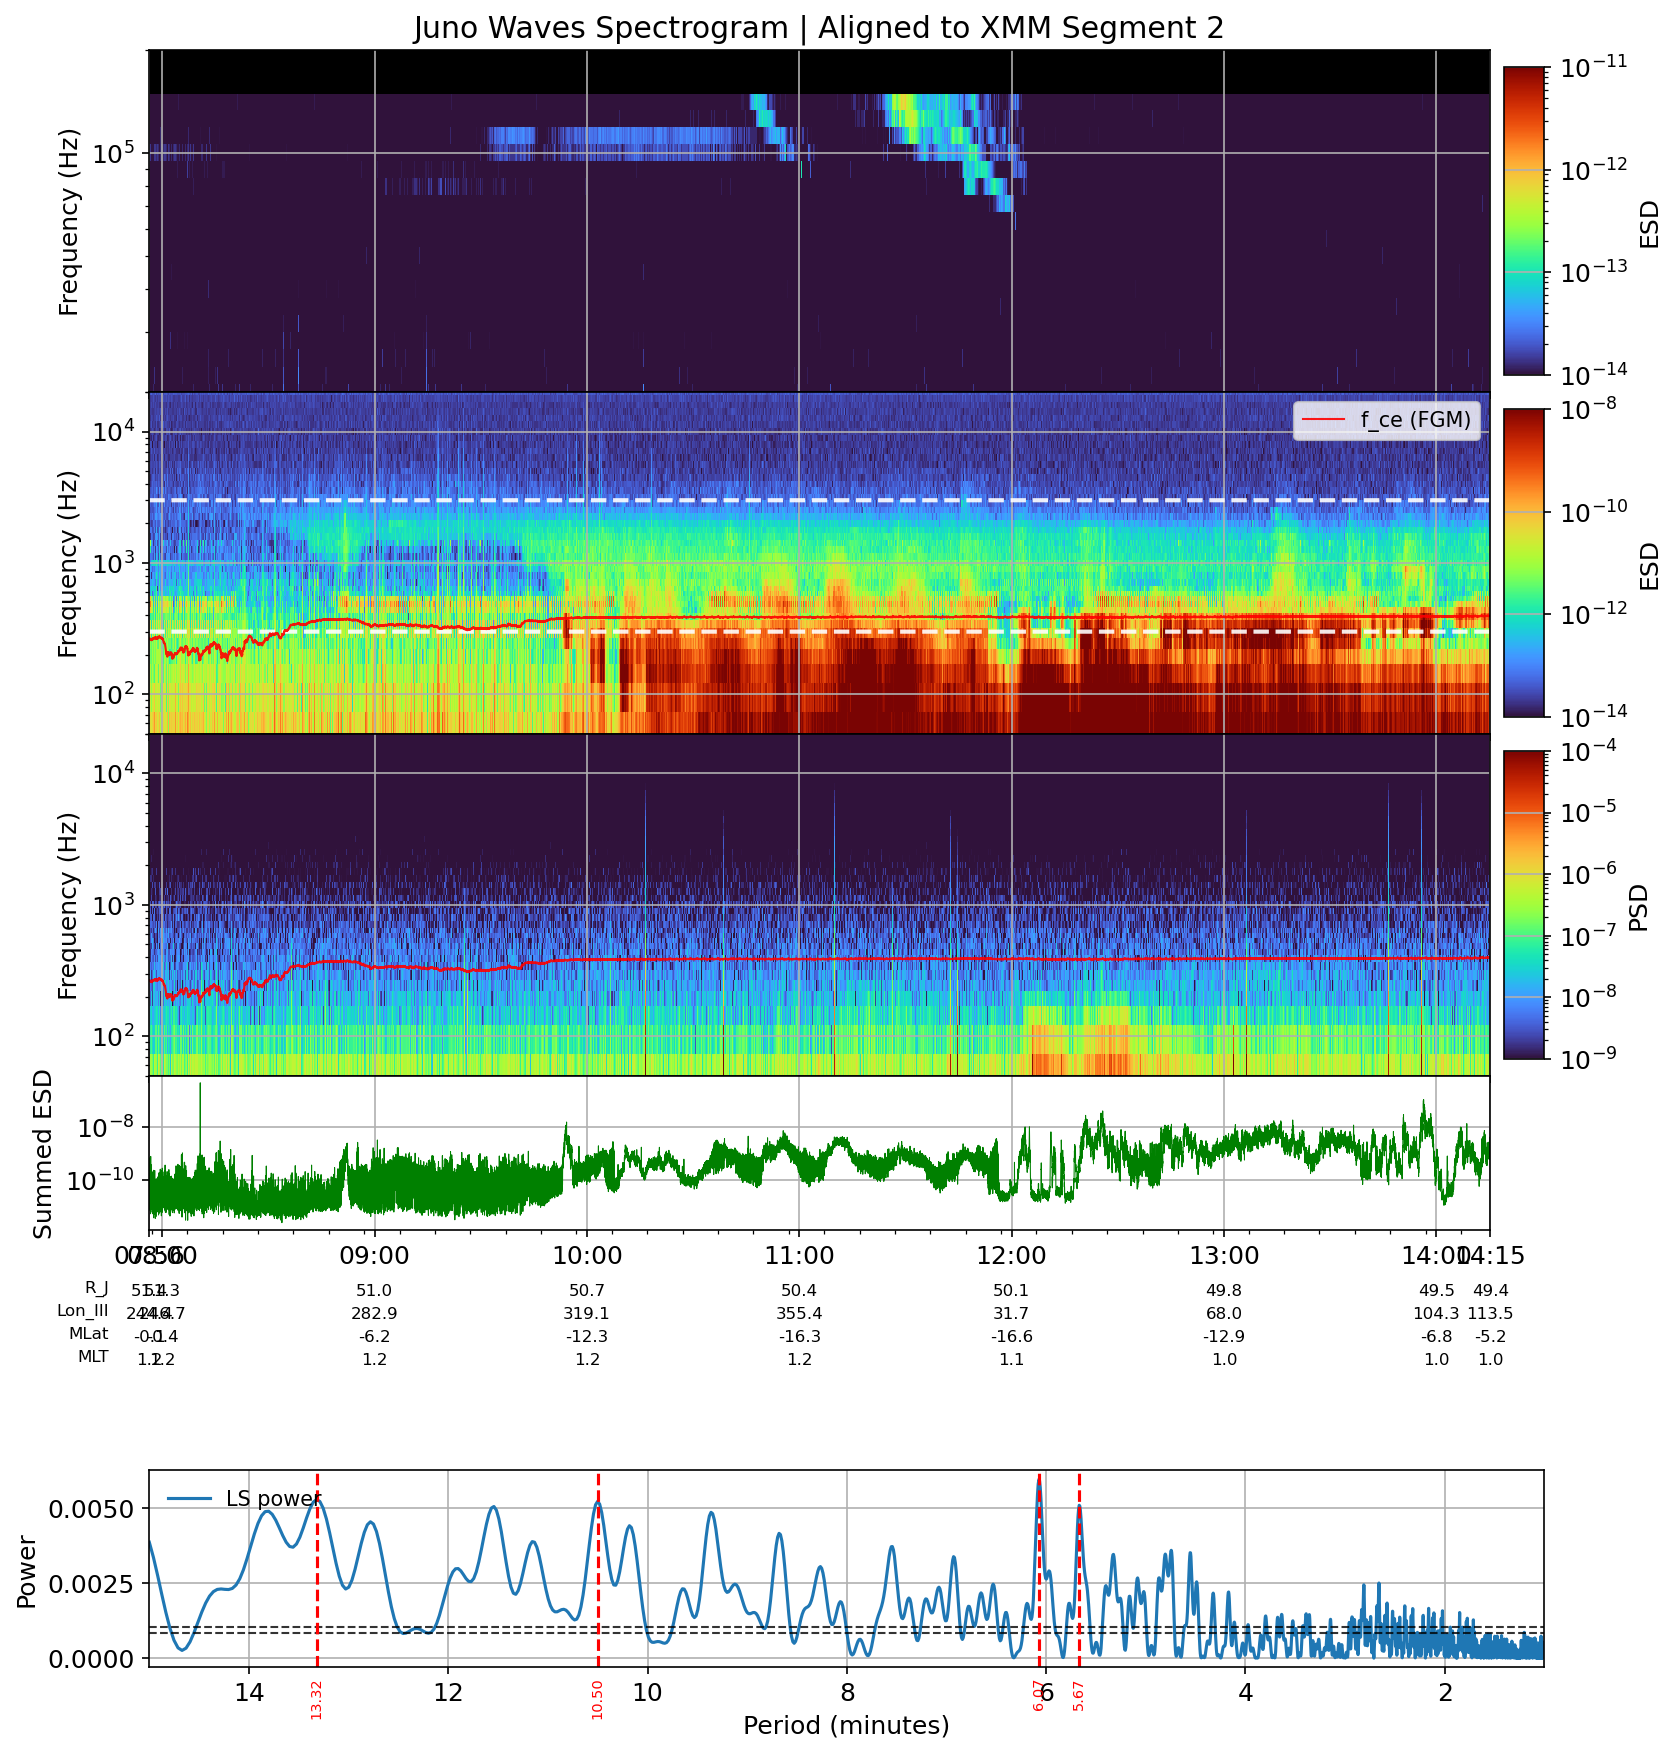


--- Plotting XMM Segment 3 (Binned at 30.0s) ---


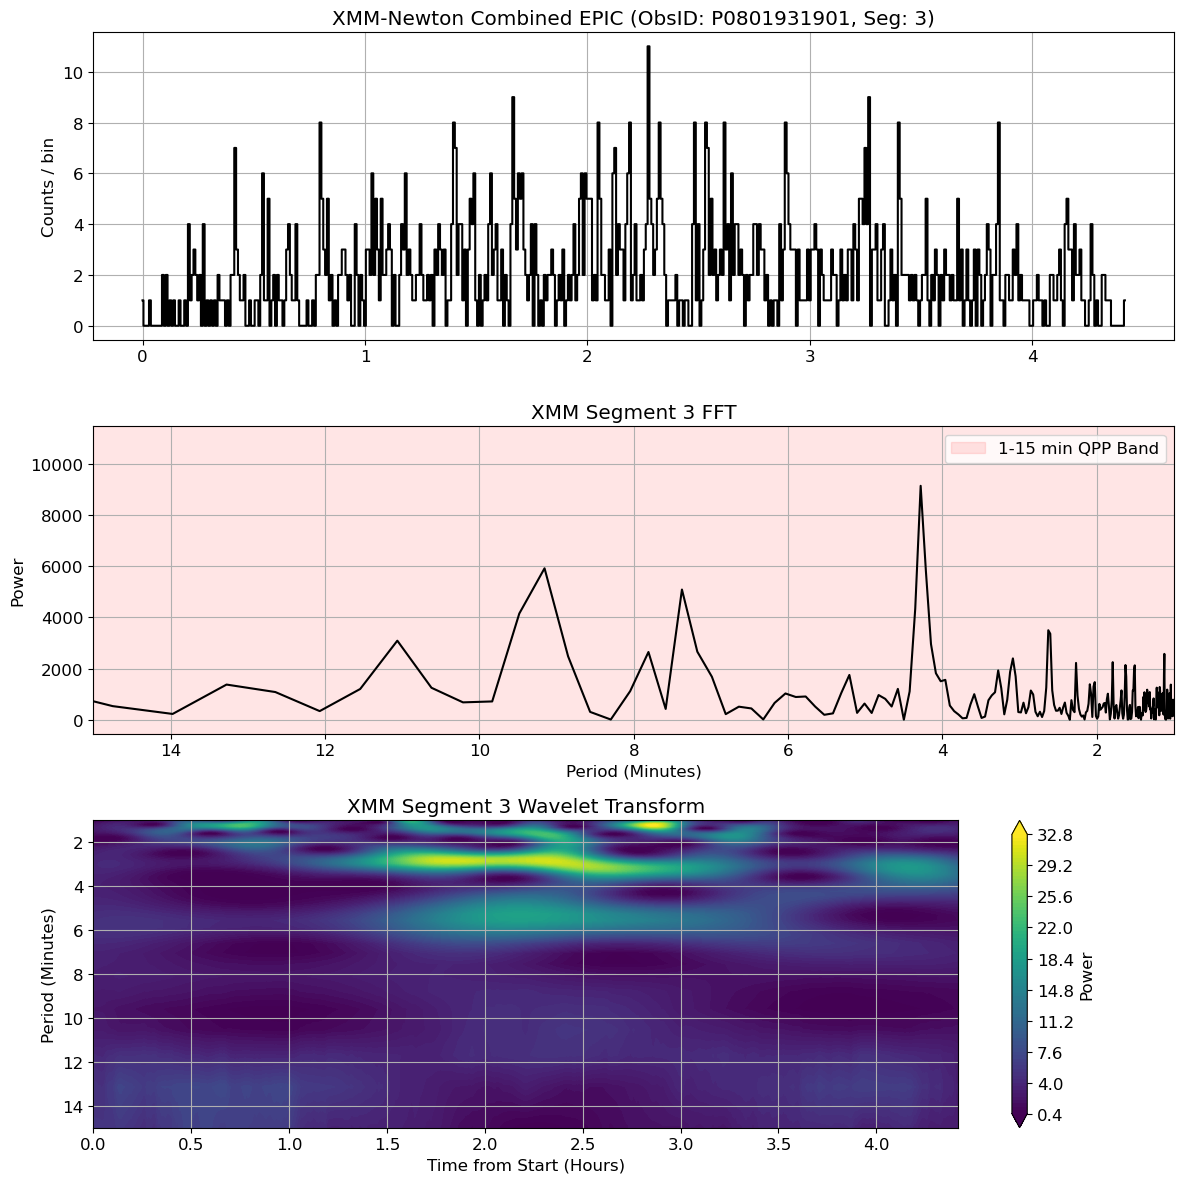


--- Processing WAVES Spectrogram for XMM Segment 3 ---
Querying Das2 Time Range: 2019-04-02T17:51:25.574Z to 2019-04-02T22:16:25.574Z


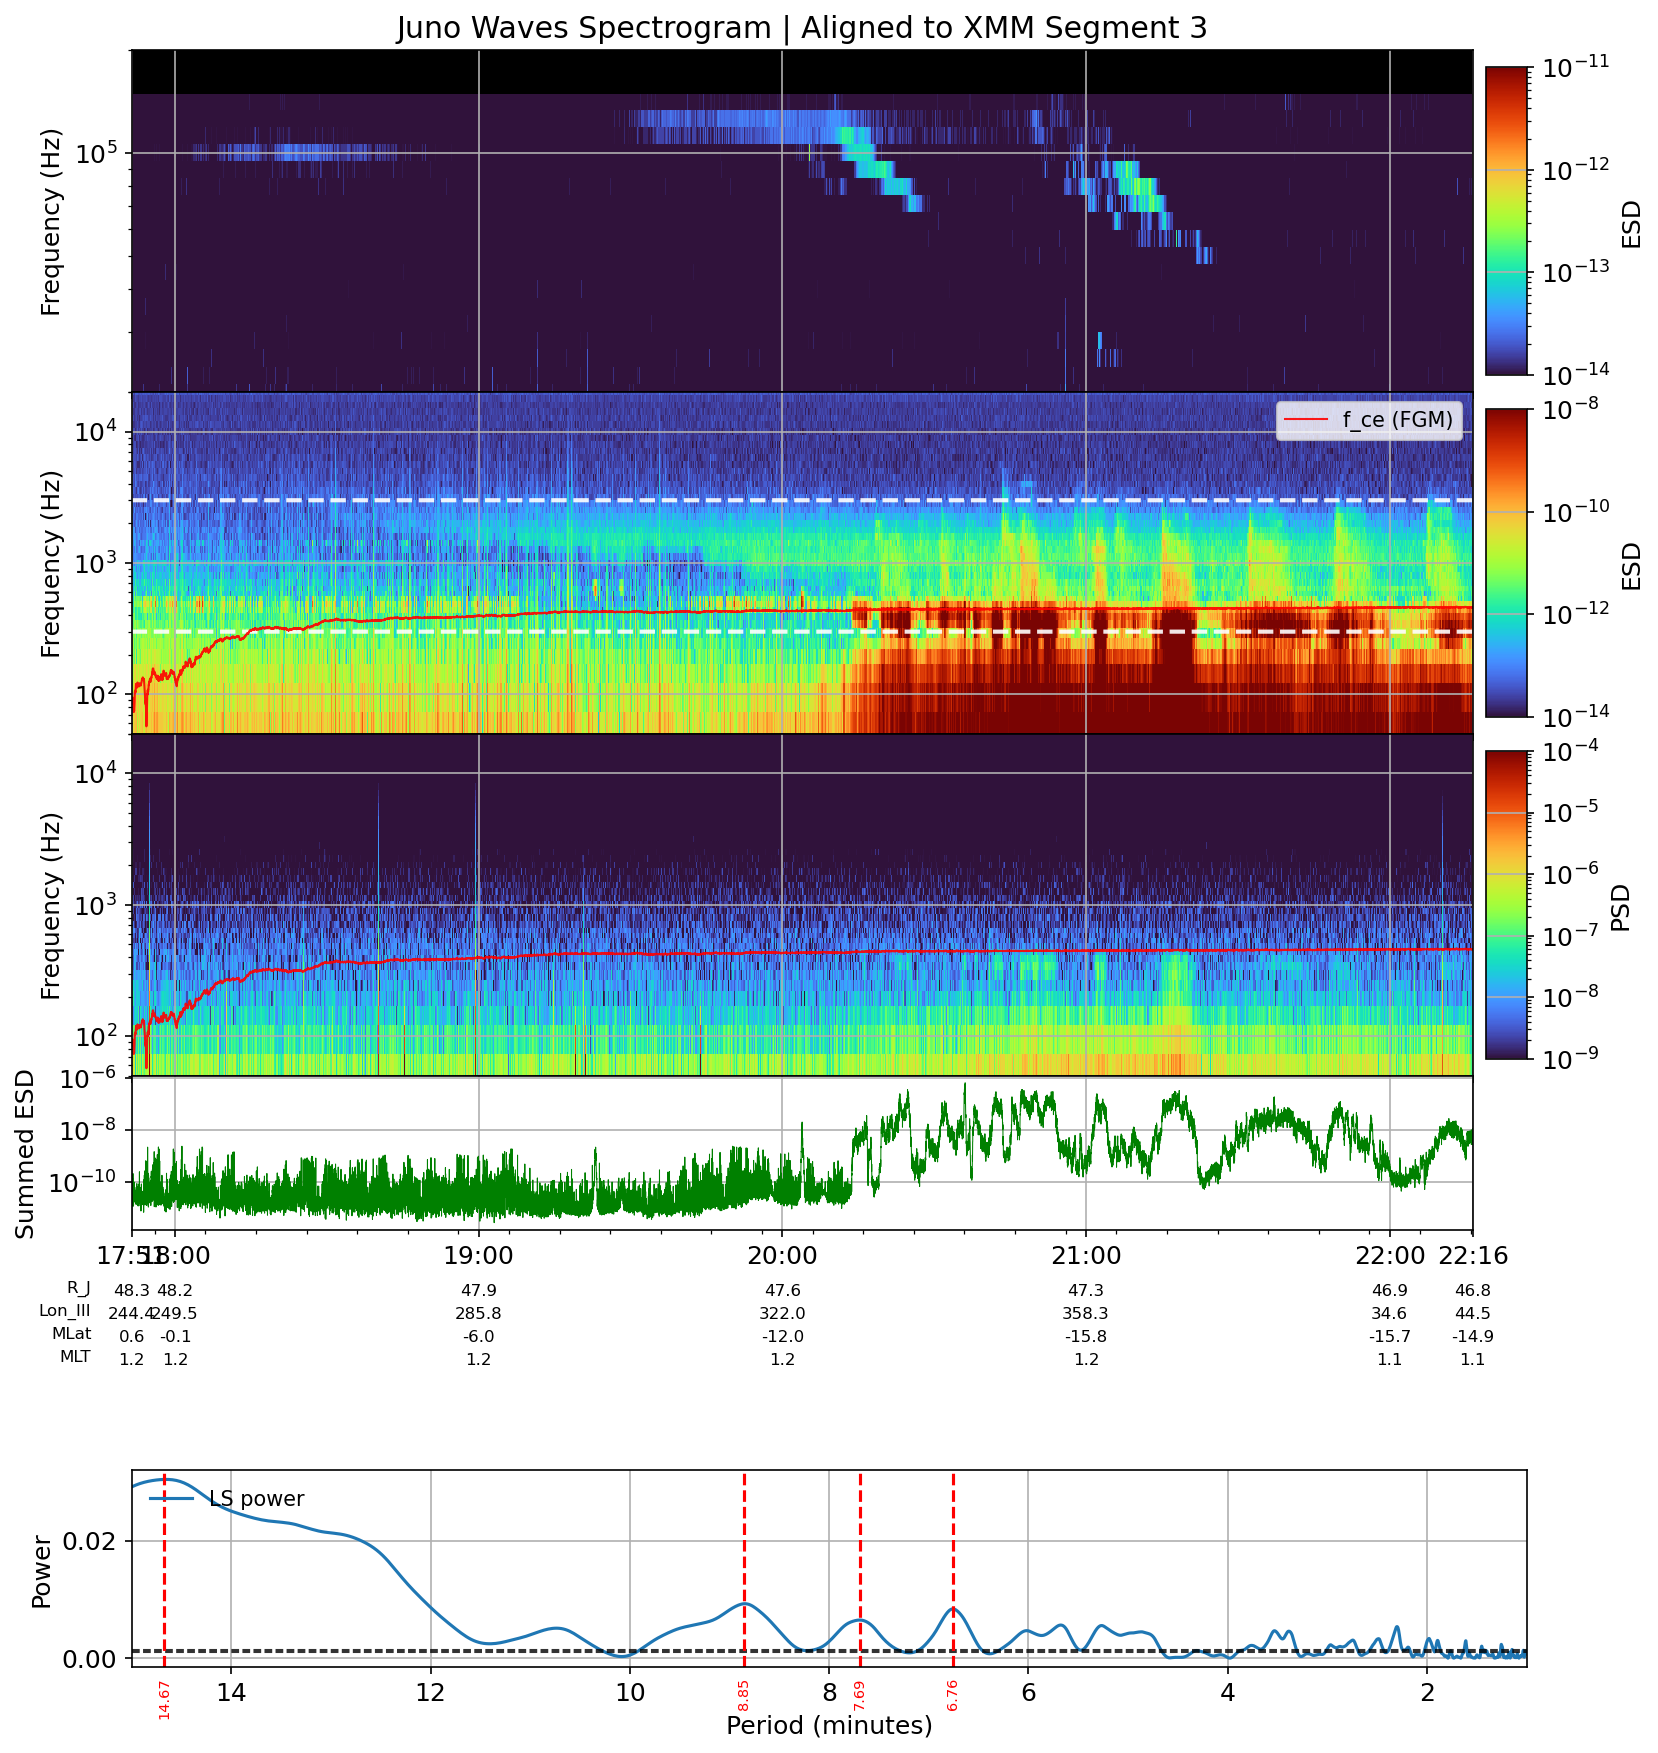

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as pe
import scipy.signal as signal
from scipy.signal import find_peaks
from scipy.fft import rfft, rfftfreq
from astropy.io import fits
from astropy.time import Time
from astropy.table import Table
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u
from astropy.timeseries import LombScargle
from das2 import get_source
import das2
import warnings

warnings.filterwarnings('ignore')
plt.rcParams.update({'font.size': 12, 'axes.grid': True, 'figure.autolayout': True})

# --- Configuration ---
# --- Configuration ---
XMM_OBS_ID = 'P0801931901'
# Replace these with your local file paths or data directory structures
XMM_EVENT_FILE_PN = f"Data_Files/Fenn_Data/EPIC_{XMM_OBS_ID}_PN_North_RFT.fit"
XMM_EVENT_FILE_M1 = f"Data_Files/Fenn_Data/EPIC_{XMM_OBS_ID}_M1_North_RFT.fit"
XMM_EVENT_FILE_M2 = f"Data_Files/Fenn_Data/EPIC_{XMM_OBS_ID}_M2_North_RFT.fit"
xmm_files = [XMM_EVENT_FILE_PN, XMM_EVENT_FILE_M1, XMM_EVENT_FILE_M2]
# Temporal binning and filtering (in seconds)
BIN_SIZE = 30.0
MIN_PERIOD_SEC = 60.0    # 1 minute
MAX_PERIOD_SEC = 900.0   # 15 minutes

# Das2 API URIs
SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
SERVER_URL_EFC   = "tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2"
SERVER_URL_EPH   = "tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2"

WAVES_FIG_OUTDIR = "WAVES_FIGS"
os.makedirs(WAVES_FIG_OUTDIR, exist_ok=True)

# --- Standard Signal Processing Functions ---
def compute_and_plot_fft(time_array, data_array, dt, ax, title="FFT Power Spectrum"):
    """Detrends data, applies a Hanning window, and plots the FFT."""
    detrended = signal.detrend(data_array)
    window = signal.windows.hann(len(detrended))
    windowed_data = detrended * window
    
    yf = rfft(windowed_data)
    xf = rfftfreq(len(windowed_data), d=dt)
    power = np.abs(yf)**2
    
    periods_min = (1.0 / xf[1:]) / 60.0 
    power = power[1:] 
    
    ax.plot(periods_min, power, color='k')
    ax.set_xlim(MAX_PERIOD_SEC/60.0, MIN_PERIOD_SEC/60.0)
    ax.set_xlabel('Period (Minutes)')
    ax.set_ylabel('Power')
    ax.set_title(title)
    
    ax.axvspan(1, 15, color='red', alpha=0.1, label='1-15 min QPP Band')
    ax.legend()

def compute_and_plot_cwt(time_array, data_array, dt, ax, title="Continuous Wavelet Transform (Morlet)"):
    """Computes and plots the CWT to show temporal evolution of periodicities."""
    detrended = signal.detrend(data_array)
    
    frequencies = np.linspace(1/MAX_PERIOD_SEC, 1/MIN_PERIOD_SEC, 100)
    w0 = 6.0
    widths = w0 * 2 * np.pi / (2 * np.pi * frequencies * dt)
    
    cwtm = signal.cwt(detrended, signal.morlet2, widths, w=w0)
    power = np.abs(cwtm)**2
    
    t_hours = (time_array - time_array[0]) / 3600.0
    periods_min = (1.0 / frequencies) / 60.0
    
    T, P = np.meshgrid(t_hours, periods_min)
    
    c = ax.contourf(T, P, power, 100, cmap='viridis', extend='both')
    ax.set_ylabel('Period (Minutes)')
    ax.set_xlabel('Time from Start (Hours)')
    ax.set_title(title)
    ax.set_ylim(15, 1)
    plt.colorbar(c, ax=ax, label='Power')

# --- XMM-Newton Gap Detection & Binning Pipeline ---
def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices

def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh: return 'low'
    elif total < high_thresh: return 'medium'
    return 'high'

def dynamic_bin_size(category: str, base_bin: int = 10):
    if category == 'low': return base_bin * 4
    elif category == 'medium': return base_bin * 2
    return base_bin

def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    bins0 = np.arange(float(np.nanmin(raw_segment)), float(np.nanmax(raw_segment)) + base_bin, base_bin)
    counts0, _ = np.histogram(raw_segment, bins=bins0)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    bins = np.arange(float(np.nanmin(raw_segment)), float(np.nanmax(raw_segment)) + seg_bin, seg_bin)
    hist_counts, edges = np.histogram(raw_segment, bins=bins)
    hist_centers = edges[:-1] + 0.5 * seg_bin
    
    return seg_bin, hist_centers, hist_counts, category

def load_all_segments_xmm(event_files, gap_threshold_s=3600.0, base_bin=10):
    list_cxc = []
    for file in event_files:
        try:
            data = Table.read(file, format="fits")
            t = Time(data['TIME'], format='cxcsec', scale='tt')
            
            with solar_system_ephemeris.set('de432s'):
                jup = get_body_barycentric('jupiter', t)
                xmm = get_body_barycentric('earth', t) 
                
            distance_au = (jup - xmm).norm()
            light_time_s = (distance_au.to('m') / c).to('s').value
            
            corrected_t = t - light_time_s * u.s
            list_cxc.append(corrected_t.cxcsec)
        except FileNotFoundError:
            print(f"Warning: {file} not found. Skipping.")
            continue
            
    if not list_cxc:
        print("No XMM files loaded. Generating mock data for testing layout.")
        t_mock = np.arange(0, 7200, 30)
        counts_mock = 100 + 20*np.sin(2*np.pi*t_mock/240) + np.random.normal(0,5, len(t_mock))
        return [{'segment_id': 1, 't_binned': t_mock, 'counts_binned': counts_mock, 'bin_size': 30, 'category': 'high'}]
        
    combined_times = np.concatenate(list_cxc)
    t_sorted = combined_times[np.argsort(combined_times)]
    
    _, gap_idx = find_gaps(t_sorted, threshold=gap_threshold_s)
    split_pts = np.concatenate(([0], gap_idx + 1, [len(t_sorted)]))
    
    segment_data = []
    seg_id = 1 
    for i in range(len(split_pts) - 1):
        seg = t_sorted[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            seg_bin, t_binned, counts_binned, category = prepare_segment_bins(seg, base_bin)
            segment_data.append({
                'segment_id': seg_id,
                't_binned': t_binned,
                'counts_binned': counts_binned,
                'bin_size': seg_bin,
                'category': category
            })
            seg_id += 1
            
    return segment_data

# --- WAVES Das2 Fetch & Plotting Routine ---
def add_inset_cbar(ax, im, label, *, height="55%", width="2.5%", pad=0.02):
    cax = inset_axes(ax, width=width, height=height, loc="center right",
                     bbox_to_anchor=(0, 0, 1, 1), bbox_transform=ax.transAxes, borderpad=0.6)
    cb = ax.figure.colorbar(im, cax=cax)
    cb.set_label(label)
    cb.ax.tick_params(labelsize=8)
    return cb

def shrink_cax(cax, frac=0.60):
    pos = cax.get_position()
    new_h = pos.height * frac
    new_y = pos.y0 + (pos.height - new_h) / 2
    cax.set_position([pos.x0, new_y, pos.width, new_h])

def make_waves_segment(start_time, end_time, label="segment", 
                       server_url=SERVER_URL_WAVES, whis_min=300.0, whis_max=3000.0,
                       period_min=1.0, period_max=15.0, peak_detect_min=2.5, num_peaks=4, ls_nfreq=5000,
                       plot_fce=True, plot_b_panel=True):
    
    source = get_source(server_url)
    ds = source.get({'time': (start_time, end_time)})
    if len(ds) < 2:
        print(f"Expected at least two datasets from DAS2 for {label}. Skipping.")
        return
    
    whis = ds[0]
    middle = ds[1]

    def extract_arrays(d):
        f_arr = d['frequency']['center'].array
        freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr
        t_arr = d['Time']['center'].array
        times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr
        spec = d['spec_dens']['center'].array.squeeze()
        if spec.ndim != 2: raise ValueError("spec_dens not 2D")
        if spec.shape[1] != freqs.size: spec = spec.T
        return (np.array(times, dtype='datetime64[ms]'), np.asarray(freqs, float), np.asarray(spec, float))

    times, freqs, spec = extract_arrays(whis)
    times_mid, freqs_mid, spec_mid = extract_arrays(middle)

    spec_plot = spec.copy()
    spec_plot[~np.isfinite(spec_plot)] = np.nan
    spec_plot[spec_plot <= 0] = np.nan

    spec_mid_plot = spec_mid.copy()
    spec_mid_plot[~np.isfinite(spec_mid_plot)] = np.nan
    spec_mid_plot[spec_mid_plot <= 0] = np.nan

    times_b = freqs_b = spec_b = spec_b_plot = None
    if plot_b_panel:
        try:
            ds_b = source.get({'time': (start_time, end_time, 1.0), 'b': True})
            if len(ds_b) > 0:
                times_b, freqs_b, spec_b = extract_arrays(ds_b[0])
                spec_b_plot = spec_b.copy()
                spec_b_plot[~np.isfinite(spec_b_plot)] = np.nan
                spec_b_plot[spec_b_plot <= 0] = np.nan
            else:
                plot_b_panel = False
        except Exception as e:
            print(f"Failed to retrieve magnetic dataset: {e}")
            plot_b_panel = False

    mask_band = (freqs >= whis_min) & (freqs <= whis_max)
    sum_sd = np.nansum(spec_plot[:, mask_band], axis=1)

    t0 = times[0]
    t_sec = (times - t0) / np.timedelta64(1, 's')
    dtcad = float(np.nanmedian(np.diff(t_sec)))
    
    coeff = np.polyfit(t_sec, sum_sd, 1)
    trend = np.polyval(coeff, t_sec)
    resid0 = sum_sd - trend - np.nanmean(sum_sd - trend)

    fmin, fmax = 1.0 / (period_max * 60.0), 1.0 / (period_min * 60.0)
    freq = np.linspace(fmin, fmax, ls_nfreq)
    ls = LombScargle(t_sec, resid0, normalization="standard", center_data=False)
    power = ls.power(freq)
    periods_ls = (1.0 / freq) / 60.0
    
    order = np.argsort(periods_ls)
    periods_ls, power_ls = periods_ls[order], power[order]
    mask_p = (periods_ls >= period_min) & (periods_ls <= period_max)
    periods_m, pow_m = periods_ls[mask_p], power_ls[mask_p]

    peaks, _ = find_peaks(pow_m)
    peak_periods = periods_m[peaks[np.argsort(pow_m[peaks])][-num_peaks:]] if peaks.size > 0 else np.array([])
    peak_periods = peak_periods[peak_periods >= peak_detect_min]

    try:
        thr_10 = ls.false_alarm_level(0.10, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax)
    except:
        thr_10 = ls.false_alarm_level(0.10, method="naive", minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="naive", minimum_frequency=fmin, maximum_frequency=fmax)

    fig = plt.figure(figsize=(12, 14), dpi=150)
    outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[6, 1], hspace=0.35)
    inner_gs = outer_gs[0].subgridspec(4, 2, height_ratios=[1, 1, 1, 0.45], width_ratios=[1, 0.03], wspace=0.02, hspace=0.00)

    ax_spec_mid = fig.add_subplot(inner_gs[0, 0])
    ax_spec     = fig.add_subplot(inner_gs[1, 0], sharex=ax_spec_mid)
    ax_bspec    = fig.add_subplot(inner_gs[2, 0], sharex=ax_spec_mid)
    ax_ts       = fig.add_subplot(inner_gs[3, 0], sharex=ax_spec_mid)
    ax_fft      = fig.add_subplot(outer_gs[1])

    cax_mid = fig.add_subplot(inner_gs[0, 1])
    cax_wh  = fig.add_subplot(inner_gs[1, 1])
    cax_b   = fig.add_subplot(inner_gs[2, 1])
    cax_ts  = fig.add_subplot(inner_gs[3, 1])
    cax_ts.axis("off")

    im_waves_mid = ax_spec_mid.pcolormesh(times_mid, freqs_mid, spec_mid_plot.T, norm=LogNorm(vmin=1e-14, vmax=1e-11), cmap="turbo", shading="nearest")
    ax_spec_mid.set_ylim(2e4, 2e5)
    ax_spec_mid.set_yscale("log")
    ax_spec_mid.set_facecolor("black")
    ax_spec_mid.set_ylabel("Frequency (Hz)")
    ax_spec_mid.set_title(f"Juno Waves Spectrogram | {label}")
    cb_mid = fig.colorbar(im_waves_mid, cax=cax_mid)
    cb_mid.set_label('ESD')
    shrink_cax(cax_mid, frac=0.90)

    im_waves_wh = ax_spec.pcolormesh(times, freqs, spec_plot.T, norm=LogNorm(vmin=1e-14, vmax=1e-8), cmap="turbo", shading="nearest")
    ax_spec.set_ylim(5e1, 2e4)
    ax_spec.set_yscale("log")
    ax_spec.set_facecolor("black")
    ax_spec.set_ylabel("Frequency (Hz)")
    cb_wh = fig.colorbar(im_waves_wh, cax=cax_wh)
    cb_wh.set_label('ESD')
    shrink_cax(cax_wh, frac=0.90)

    ax_spec.plot(times, np.full(times.shape, whis_min), "--w", lw=2, alpha=0.9)
    ax_spec.plot(times, np.full(times.shape, whis_max), "--w", lw=2, alpha=0.9)

    if plot_b_panel and spec_b_plot is not None:
        im_b = ax_bspec.pcolormesh(times_b, freqs_b, spec_b_plot.T, norm=LogNorm(vmin=1e-9, vmax=1e-4), cmap="turbo", shading="nearest")
        ax_bspec.set_ylim(5e1, 2e4)
        ax_bspec.set_yscale("log")
        ax_bspec.set_facecolor("black")
        ax_bspec.set_ylabel("Frequency (Hz)")
        cb_b = fig.colorbar(im_b, cax=cax_b)
        cb_b.set_label('PSD')
        shrink_cax(cax_b, frac=0.9)
    else:
        ax_bspec.axis("off")
        cax_b.axis("off")

    for ax in [ax_spec_mid, ax_spec, ax_bspec]:
        ax.tick_params(axis="x", labelbottom=False)

    axes_for_overlays = [ax_spec_mid, ax_spec]
    if plot_b_panel and ax_bspec.axison:
        axes_for_overlays.append(ax_bspec)

    if plot_fce:
        try:
            efc_source = das2.get_source(SERVER_URL_EFC)
            ds_efc = efc_source.get({"time": (start_time, end_time)})[0]
            efc_freq = np.asarray(ds_efc["fce"]["center"].array, float)
            efc_time = np.array(ds_efc["time"]["center"].array, dtype="datetime64[ms]")
            mask_fce = np.isfinite(efc_freq) & (efc_freq > 0)
            for ax_ov in axes_for_overlays:
                ax_ov.plot(efc_time[mask_fce], efc_freq[mask_fce], color="red", linewidth=1.0, alpha=0.9, label="f_ce (FGM)" if ax_ov is ax_spec else None)
        except Exception as e:
            print(f"Failed to load FGM f_ce: {e}")

    ax_spec.legend(loc="upper right", frameon=True, ncols=2, fontsize="small")

    ax_ts.plot(times, sum_sd, linewidth=0.5, color="green")
    ax_ts.set_ylabel("Summed ESD")
    ax_ts.set_xlim(times[0], times[-1])
    ax_ts.set_yscale("log")

    major, minor = mdates.HourLocator(interval=1), mdates.MinuteLocator(interval=10)
    ax_ts.xaxis.set_major_locator(major)
    ax_ts.xaxis.set_minor_locator(minor)
    ax_ts.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

    try:
        eph_src = get_source(SERVER_URL_EPH)
        ds_eph  = eph_src.get({"time": (start_time, end_time, int(max(1, round(dtcad))))})[0]
        rad   = ds_eph["radius"]["center"].array
        lon3  = ds_eph["long"]["center"].array
        mlatE = ds_eph["mlat"]["center"].array
        mltE  = ds_eph["mlt"]["center"].array
        if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
            mltE = (mltE / np.timedelta64(1, "h")).astype(float)

        t0h = times[0].astype("datetime64[h]")
        t1h = times[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
        maj = np.arange(t0h, t1h, np.timedelta64(1, "h"))
        all_ticks = np.unique(np.concatenate(([times[0]], maj, [times[-1]])))
        all_tick_nums = mdates.date2num([t.tolist() for t in all_ticks])
        
        ax_ts.xaxis.set_major_locator(FixedLocator(all_tick_nums))
        idx_eph = [np.argmin(np.abs(times - mt)) for mt in all_ticks]
        
        for j, (lab, arr) in enumerate(zip(["R_J", "Lon_III", "MLat", "MLT"], [rad, lon3, mlatE, mltE])):
            sax = ax_ts.secondary_xaxis(-0.15 * (j + 2), functions=(lambda x: x, lambda x: x))
            sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
            sax.set_xticklabels([f"{v:.1f}" for v in arr[idx_eph]], rotation=0, va="top", fontsize=8)
            sax.spines["bottom"].set_visible(False)
            sax.tick_params(axis="x", length=0)
            txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
            txt.set_x(-0.03)
            txt.set_ha("right")
    except Exception as e:
        print(f"Failed to load Ephemeris: {e}")

    ax_fft.plot(periods_m, pow_m, label="LS power")
    ax_fft.axhline(thr_10, ls="--", lw=1, color="k", alpha=0.8)
    ax_fft.axhline(thr_01, ls="--", lw=1, color="k", alpha=0.8)
    for p in peak_periods:
        ax_fft.axvline(p, ls="--", color="red")
        ax_fft.text(p, -0.05, f"{p:.2f}", transform=ax_fft.get_xaxis_transform(), rotation=90, va="top", ha="center", color="red", fontsize=7)
    ax_fft.set_xlim(period_max, period_min)
    ax_fft.set_xlabel("Period (minutes)")
    ax_fft.set_ylabel("Power")
    ax_fft.legend(loc="upper left", frameon=False, ncols=2, fontsize="small")

    plt.tight_layout(rect=[0, 0.02, 1, 0.96])
    plt.show()

# --- Execution Loop ---
if __name__ == "__main__":
    all_segments = load_all_segments_xmm(xmm_files, gap_threshold_s=3600.0, base_bin=BIN_SIZE)

    for seg in all_segments:
        t_xmm = seg['t_binned']
        counts_xmm = seg['counts_binned']
        actual_bin_size = seg['bin_size']
        seg_id = seg['segment_id']
        
        print(f"\n--- Plotting XMM Segment {seg_id} (Binned at {actual_bin_size}s) ---")
        fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12))

        t_hours = (t_xmm - t_xmm[0]) / 3600.0 
        ax1.plot(t_hours, counts_xmm, color='black', drawstyle='steps-mid')
        ax1.set_title(f'XMM-Newton Combined EPIC (ObsID: {XMM_OBS_ID}, Seg: {seg_id})')
        ax1.set_ylabel('Counts / bin')

        compute_and_plot_fft(t_xmm, counts_xmm, dt=actual_bin_size, ax=ax2, title=f'XMM Segment {seg_id} FFT')
        compute_and_plot_cwt(t_xmm, counts_xmm, dt=actual_bin_size, ax=ax3, title=f'XMM Segment {seg_id} Wavelet Transform')

        plt.tight_layout()
        plt.show()

        # Convert segment bounds from cxcsec to standard Das2 ISO format with trailing Z
        start_time_iso = Time(t_xmm[0], format='cxcsec').isot + 'Z'
        end_time_iso = Time(t_xmm[-1], format='cxcsec').isot + 'Z'
        
        print(f"\n--- Processing WAVES Spectrogram for XMM Segment {seg_id} ---")
        print(f"Querying Das2 Time Range: {start_time_iso} to {end_time_iso}")
        
        make_waves_segment(
            start_time=start_time_iso,
            end_time=end_time_iso,
            label=f"Aligned to XMM Segment {seg_id}",
            plot_fce=True,
            plot_b_panel=True
        )